# B4 — Conditional entropy in both sequence directions

**Deliverable:** one entropy value per direction and a correct interpretation.
B4 depends on B3's `indus.ngrams` module. Select `.venv/bin/python`, then run all.
The branch and PR are stacked on B3 so the review contains only B4 changes.

Source: 1,837 filtered unique ICIT inscriptions, Wells IDs. `load_sequences()`
gives the project's reading order (right to left on the impression); reversing
each sequence supplies the opposite direction. No raw files are edited.
These are unsmoothed empirical full-corpus entropies, not held-out scores.

## 1. Entropy means uncertainty, measured in bits

If the next sign is certain, entropy is 0. Two equally likely options give
1 bit; four equally likely options give 2 bits. A skewed distribution is less
uncertain than equally likely options of the same number.

For probabilities `p`, `H = -sum(p * log2(p))`. We omit zero terms, whose
contribution is defined as zero, before taking logarithms. This avoids `log(0)`.
For our toy row `[0.2,0.2,0.6]`, entropy is about 1.371 bits.
This measures a distribution, not sign meaning or grammatical function.

In [1]:
import sys
import json
import math
import hashlib
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from indus.data import load_sequences, REPO_ROOT, SEQUENCES_FILE
from indus.ngrams import count_ngrams, transition_matrices
from indus.entropy import (entropy_from_counts, row_entropy_table,
                           conditional_entropy, entropy_summary)

print("Interpreter:", sys.executable)
assert math.isclose(entropy_from_counts([5,0]),0,abs_tol=1e-12)
assert math.isclose(entropy_from_counts([1,1]),1,abs_tol=1e-12)
assert math.isclose(entropy_from_counts([1,1,1,1]),2,abs_tol=1e-12)
print("Entropy of [20%,20%,60%]:", entropy_from_counts([20,20,60]))

Interpreter: /home/devambhavsar/ML/AI_Project/.venv/bin/python
Entropy of [20%,20%,60%]: 1.3709505944546687


### What the Python does

`entropy_from_counts()` turns counts into probabilities by dividing by their
total. `values[values > 0]` keeps positive counts only. `np.log2` applies the
base-two logarithm to each probability; multiplication makes `p * log2(p)`;
`np.sum` adds those terms; the leading minus sign makes entropy nonnegative.

All-zero counts have no probability distribution, so the function rejects
them, along with negative or nonfinite counts. It does not call an undefined
distribution certain merely because no evidence was recorded.

## 2. Average row entropies using outgoing observations

`H(next | current) = sum_X weight(X) * H(next | X)`.
The weight is the outgoing pair count of X divided by all 6,522 pair occurrences.
It is not an equal average across sign types. A rare row does not get the same
influence as one seen hundreds of times.

Undefined rows have NaN entropy, zero weight, and explicitly zero contribution.
We never calculate `0 * NaN`. If the entire corpus has no pairs, its conditional
entropy is undefined and the function rejects it.

In [2]:
# Nine deterministic observations and two uncertain observations.
hand_counts = pd.DataFrame([[9,0],[1,1]],index=[10,20],columns=[10,20])
display(row_entropy_table(hand_counts))
assert math.isclose(conditional_entropy(hand_counts),2/11,abs_tol=1e-12)
print("Weighted conditional entropy:",conditional_entropy(hand_counts))
print("An equal row average would incorrectly give 0.5 here.")
no_successor = pd.DataFrame([[0,2],[0,0]],index=[10,20],columns=[10,20])
display(row_entropy_table(no_successor))
assert conditional_entropy(no_successor) == 0

,current_wells_id,outgoing_count,pair_weight,entropy_bits,weighted_entropy_bits,entropy_defined
0,10,9.0,0.818182,-0.0,-0.000000,True
1,20,2.0,0.181818,1.0,0.181818,True


Weighted conditional entropy: 0.18181818181818182
An equal row average would incorrectly give 0.5 here.


,current_wells_id,outgoing_count,pair_weight,entropy_bits,weighted_entropy_bits,entropy_defined
0,10,2.0,1.0,-0.0,-0.0,True
1,20,0.0,0.0,NaN,0.0,False


## 3. Calculate both directions using the full vocabulary

Use B3 to count both original and reversed sequences; do not merely transpose
a probability matrix. Counts transpose, but probability denominators change.
We use all 568 types, including rare signs, not the cropped B3 heatmap.

`entropy_summary()` also computes the entropy of pair-first positions (X),
pair-second positions (Y), the joint pair distribution, and mutual information.
The marginals are distributions over pair positions, not B1's full-token
distribution. These extra quantities let us check and interpret the result.

In [3]:
sequences = load_sequences()
reading_counts, _ = transition_matrices(sequences)
reversed_sequences = [sequence[::-1] for sequence in sequences]
reversed_counts, _ = transition_matrices(reversed_sequences)
np.testing.assert_array_equal(reversed_counts.to_numpy(),reading_counts.to_numpy().T)
reading = entropy_summary(reading_counts)
reversed_result = entropy_summary(reversed_counts)
reading_rows = row_entropy_table(reading_counts)
reversed_rows = row_entropy_table(reversed_counts)
directions = pd.DataFrame([reading,reversed_result],index=["reading_RTL","reversed_LTR"])
directions.index.name = "direction"
assert reading["pair_occurrences"] == reversed_result["pair_occurrences"] == 6522
assert reading["undefined_rows"] == 42
assert math.isclose(reading_rows["pair_weight"].sum(),1,abs_tol=1e-12)
assert math.isclose(reversed_rows["pair_weight"].sum(),1,abs_tol=1e-12)
display(directions)
print("Most supported reading-order rows:")
display(reading_rows.sort_values(["outgoing_count","current_wells_id"],ascending=[False,True]).head(10))

,pair_occurrences,defined_rows,undefined_rows,conditional_entropy_bits,current_marginal_entropy_bits,next_marginal_entropy_bits,joint_entropy_bits,mutual_information_bits
direction,,,,,,,,
reading_RTL,6522.0,526,42,3.308180,7.023906,6.509039,10.332086,3.200859
reversed_LTR,6522.0,436,132,3.823046,6.509039,7.023906,10.332086,3.200859


Most supported reading-order rows:


,current_wells_id,outgoing_count,pair_weight,entropy_bits,weighted_entropy_bits,entropy_defined
1,2,453.0,0.069457,5.866657,0.407482,True
436,740,255.0,0.039098,3.637360,0.142215,True
20,32,202.0,0.030972,4.775752,0.147915,True
140,220,198.0,0.030359,5.098386,0.154781,True
154,240,179.0,0.027446,5.356358,0.147008,True
38,60,146.0,0.022386,4.949645,0.110802,True
21,33,142.0,0.021772,4.751097,0.103443,True
515,861,141.0,0.021619,1.206395,0.026081,True
152,235,133.0,0.020393,4.563361,0.093058,True
488,820,133.0,0.020393,2.681194,0.054676,True


## 4. Why this difference does not independently establish reading direction

Pick an observed pair uniformly. X is its first sign and Y its second.

```text
H(Y | X) = H(X,Y) - H(X)
H(X | Y) = H(X,Y) - H(Y)
Therefore H(Y | X) - H(X | Y) = H(Y) - H(X).
```

The same joint entropy cancels. Mutual information is also unchanged by reversal.
This exact identity applies to our unsmoothed occurrence-weighted estimator.

In finite texts, pair-first positions exclude final signs, whereas pair-second
positions exclude initial signs. Thus `first-pair count = token count - end count`
and `second-pair count = token count - start count`. Their marginal entropy
difference is the entire directional difference here, linking B4 to B2.

We can describe one direction as having lower empirical next-sign uncertainty,
but cannot use these two values alone to prove direction, language, or meaning.
This identity is a check and an interpretation requirement, not a result to hide.

In [4]:
difference = reading["conditional_entropy_bits"] - reversed_result["conditional_entropy_bits"]
marginal_difference = reading["next_marginal_entropy_bits"] - reading["current_marginal_entropy_bits"]
residual = difference - marginal_difference
assert math.isclose(difference,marginal_difference,abs_tol=1e-12)
assert math.isclose(reading["joint_entropy_bits"],reversed_result["joint_entropy_bits"],abs_tol=1e-12)
assert math.isclose(reading["mutual_information_bits"],reversed_result["mutual_information_bits"],abs_tol=1e-12)
assert math.isclose(reading["conditional_entropy_bits"],
                    reading["joint_entropy_bits"]-reading["current_marginal_entropy_bits"],abs_tol=1e-12)
tokens = Counter(sign for sequence in sequences for sign in sequence)
starts = Counter(sequence[0] for sequence in sequences)
ends = Counter(sequence[-1] for sequence in sequences)
for sign in reading_counts.index:
    assert int(reading_counts.loc[sign].sum()) == tokens[sign]-ends[sign]
    assert int(reading_counts[sign].sum()) == tokens[sign]-starts[sign]
print("Signed difference (reading minus reversed), bits:",difference)
print("Pair-marginal entropy difference, bits:",marginal_difference)
print("Identity residual, bits:",residual)

Signed difference (reading minus reversed), bits: -0.5148661854417855
Pair-marginal entropy difference, bits: -0.5148661854417851
Identity residual, bits: -4.440892098500626e-16


## 5. Show the two values with an honest caption

Both bars begin at zero and use the same scale. The caption explains the identity
rather than declaring a winning reading direction. The adopted RTL label comes
from the loader convention, not from a decision rule applied to these bars.

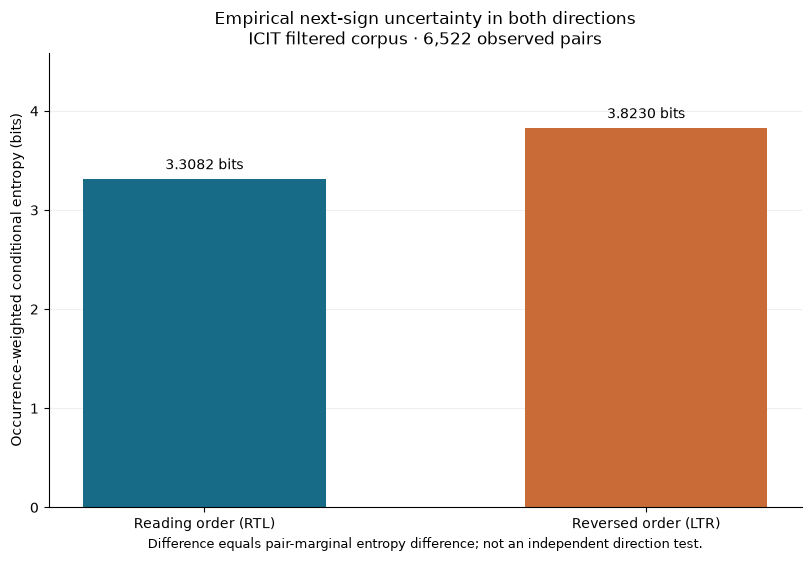

In [5]:
fig, ax = plt.subplots(figsize=(8,5.5),layout="constrained")
values = [reading["conditional_entropy_bits"],reversed_result["conditional_entropy_bits"]]
bars = ax.bar(["Reading order (RTL)","Reversed order (LTR)"],values,
              color=["#176B87","#C86B37"],width=0.55)
ax.bar_label(bars,labels=[f"{value:.4f} bits" for value in values],padding=5)
ax.set_ylim(0,max(values)*1.2)
ax.set_ylabel("Occurrence-weighted conditional entropy (bits)")
ax.set_title("Empirical next-sign uncertainty in both directions\n"
             "ICIT filtered corpus · 6,522 observed pairs",fontsize=12)
ax.spines[["top","right"]].set_visible(False)
ax.grid(axis="y",alpha=0.2)
ax.set_axisbelow(True)
ax.set_xlabel("Difference equals pair-marginal entropy difference; not an independent direction test.",fontsize=9)
figures = REPO_ROOT / "reports/figures"
figures.mkdir(parents=True,exist_ok=True)
fig.savefig(figures / "b4_direction_entropy.png",dpi=180)
plt.show()
plt.close(fig)

## 6. Check independently, export, and state the interpretation

An independent calculation sums `-(pair_count / all_pairs) * log2(pair_count /
current_sign_outgoing_count)` directly over observed pairs. This avoids the
matrix/row-entropy route and must agree.

`scripts/check_b4.py` supplies ten checks: known entropy values, invalid inputs,
occurrence weighting, undefined/no-pair cases, chain-rule and direction identities,
label/scale invariance, double reversal and full-corpus independent calculation.
B3 and the existing repository tests are run separately too.

No smoothing or held-out test is involved. Sampling/finite-data bias and corpus
filtering limit comparison with other studies; published values from another
corpus/estimator are context, not exact expected targets.

In [6]:
pairs = count_ngrams(sequences)
outgoing = Counter()
for (first,second),count in pairs.items():
    outgoing[first] += count
independent = -sum(count/6522 * math.log2(count/outgoing[first])
                   for (first,second),count in pairs.items())
assert math.isclose(independent,reading["conditional_entropy_bits"],abs_tol=1e-12)
restored_counts, _ = transition_matrices([sequence[::-1] for sequence in reversed_sequences])
pd.testing.assert_frame_equal(restored_counts,reading_counts)

interpretation = (
    f"Empirical conditional entropy is {values[0]:.4f} bits in the adopted reading order "
    f"and {values[1]:.4f} bits in reversed order; the signed difference ({difference:.4f} bits) "
    "equals the pair-marginal entropy difference and does not independently establish reading direction."
)
processed = REPO_ROOT / "data/processed/b4"
processed.mkdir(parents=True,exist_ok=True)
directions.to_csv(processed / "direction_entropies.csv")
reading_rows.to_csv(processed / "reading_row_entropies.csv",index=False,na_rep="")
reversed_rows.to_csv(processed / "reversed_row_entropies.csv",index=False,na_rep="")
saved = pd.read_csv(processed / "direction_entropies.csv",index_col=0)
pd.testing.assert_frame_equal(saved,directions,check_exact=False,rtol=1e-12,atol=1e-12)
saved_rows = pd.read_csv(processed / "reading_row_entropies.csv")
pd.testing.assert_frame_equal(saved_rows,reading_rows,check_exact=False,rtol=1e-12,atol=1e-12)
summary = {
    "dataset":"ICIT 1837 filtered unique inscriptions","numbering":"Wells",
    "estimator":"unsmoothed empirical bigram entropy, outgoing-occurrence weighted",
    "source":str(SEQUENCES_FILE.relative_to(REPO_ROOT)),
    "source_sha256":hashlib.sha256(SEQUENCES_FILE.read_bytes()).hexdigest(),
    "reading_RTL":reading,"reversed_LTR":reversed_result,
    "reading_minus_reversed_bits":difference,"pair_marginal_difference_bits":marginal_difference,
    "identity_residual_bits":residual,"independent_reading_entropy_bits":independent,
    "interpretation":interpretation
}
(processed / "summary.json").write_text(json.dumps(summary,indent=2)+"\n")
print(interpretation)
print("All notebook checks passed; outputs:",processed)
print(json.dumps(summary,indent=2))

Empirical conditional entropy is 3.3082 bits in the adopted reading order and 3.8230 bits in reversed order; the signed difference (-0.5149 bits) equals the pair-marginal entropy difference and does not independently establish reading direction.
All notebook checks passed; outputs: /home/devambhavsar/ML/AI_Project/data/processed/b4
{
  "dataset": "ICIT 1837 filtered unique inscriptions",
  "numbering": "Wells",
  "estimator": "unsmoothed empirical bigram entropy, outgoing-occurrence weighted",
  "source": "data/raw/icit_1837_sequences.csv",
  "source_sha256": "140a61e57dfaccd15867d9a00141f180a38080141b0ad18bb4262c782024f186",
  "reading_RTL": {
    "pair_occurrences": 6522.0,
    "defined_rows": 526,
    "undefined_rows": 42,
    "conditional_entropy_bits": 3.308180303636441,
    "current_marginal_entropy_bits": 7.023905659412491,
    "next_marginal_entropy_bits": 6.509039473970706,
    "joint_entropy_bits": 10.332085963048932,
    "mutual_information_bits": 3.200859170334265
  },
  "r

## 7. What to remember

Conditional entropy is an outgoing-observation-weighted average of row
uncertainty. A no-successor row is undefined, not a certain row. The two
direction values are valid descriptions of this corpus under this estimator;
their difference is completely accounted for by pair-position marginals.
This task does not discover script meanings or independently choose direction.

To reproduce checks from the project root:
`.venv/bin/python scripts/check_b4.py`,
`.venv/bin/python scripts/check_b3.py`, and
`.venv/bin/python -m pytest -q`.

Local references: `docs/TASKS.md` (B4), `data/README.md` (source/limitations),
`src/indus/ngrams.py` (B3 counts), `src/indus/entropy.py` (new maths).